**Course outline:** Unit 02 · Notebook 01 · Python

# Map Laila's reporting systems

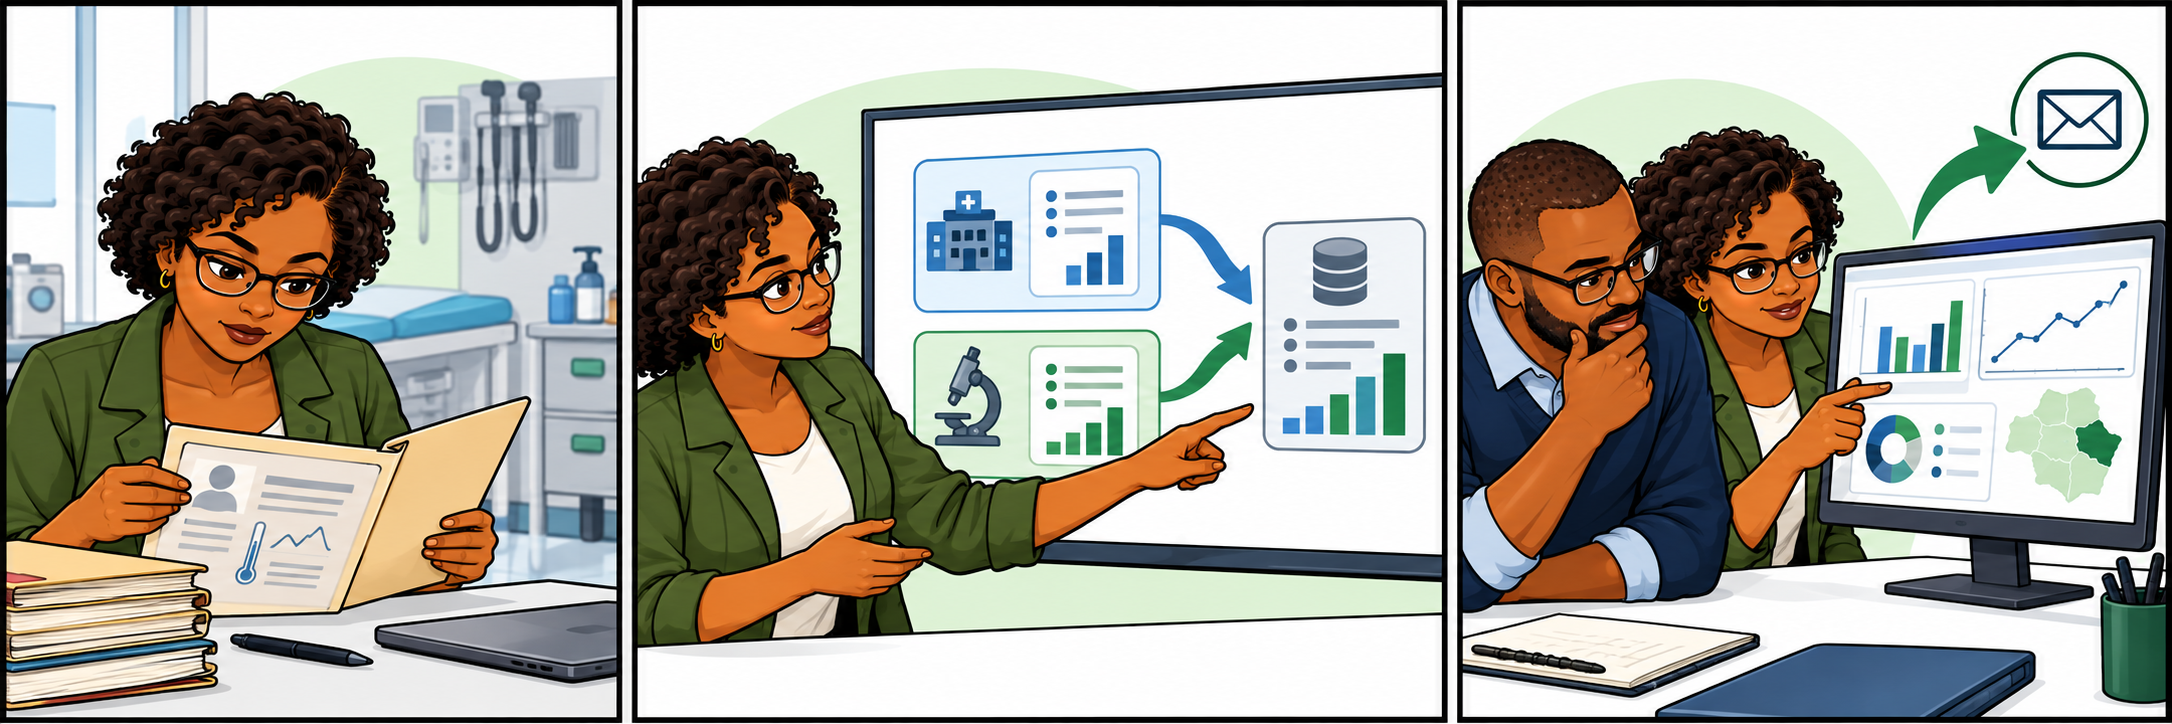

*Laila needs to know where a report begins and which systems carry it to the district. Original teaching illustration; no dialogue is taken from the slides.*

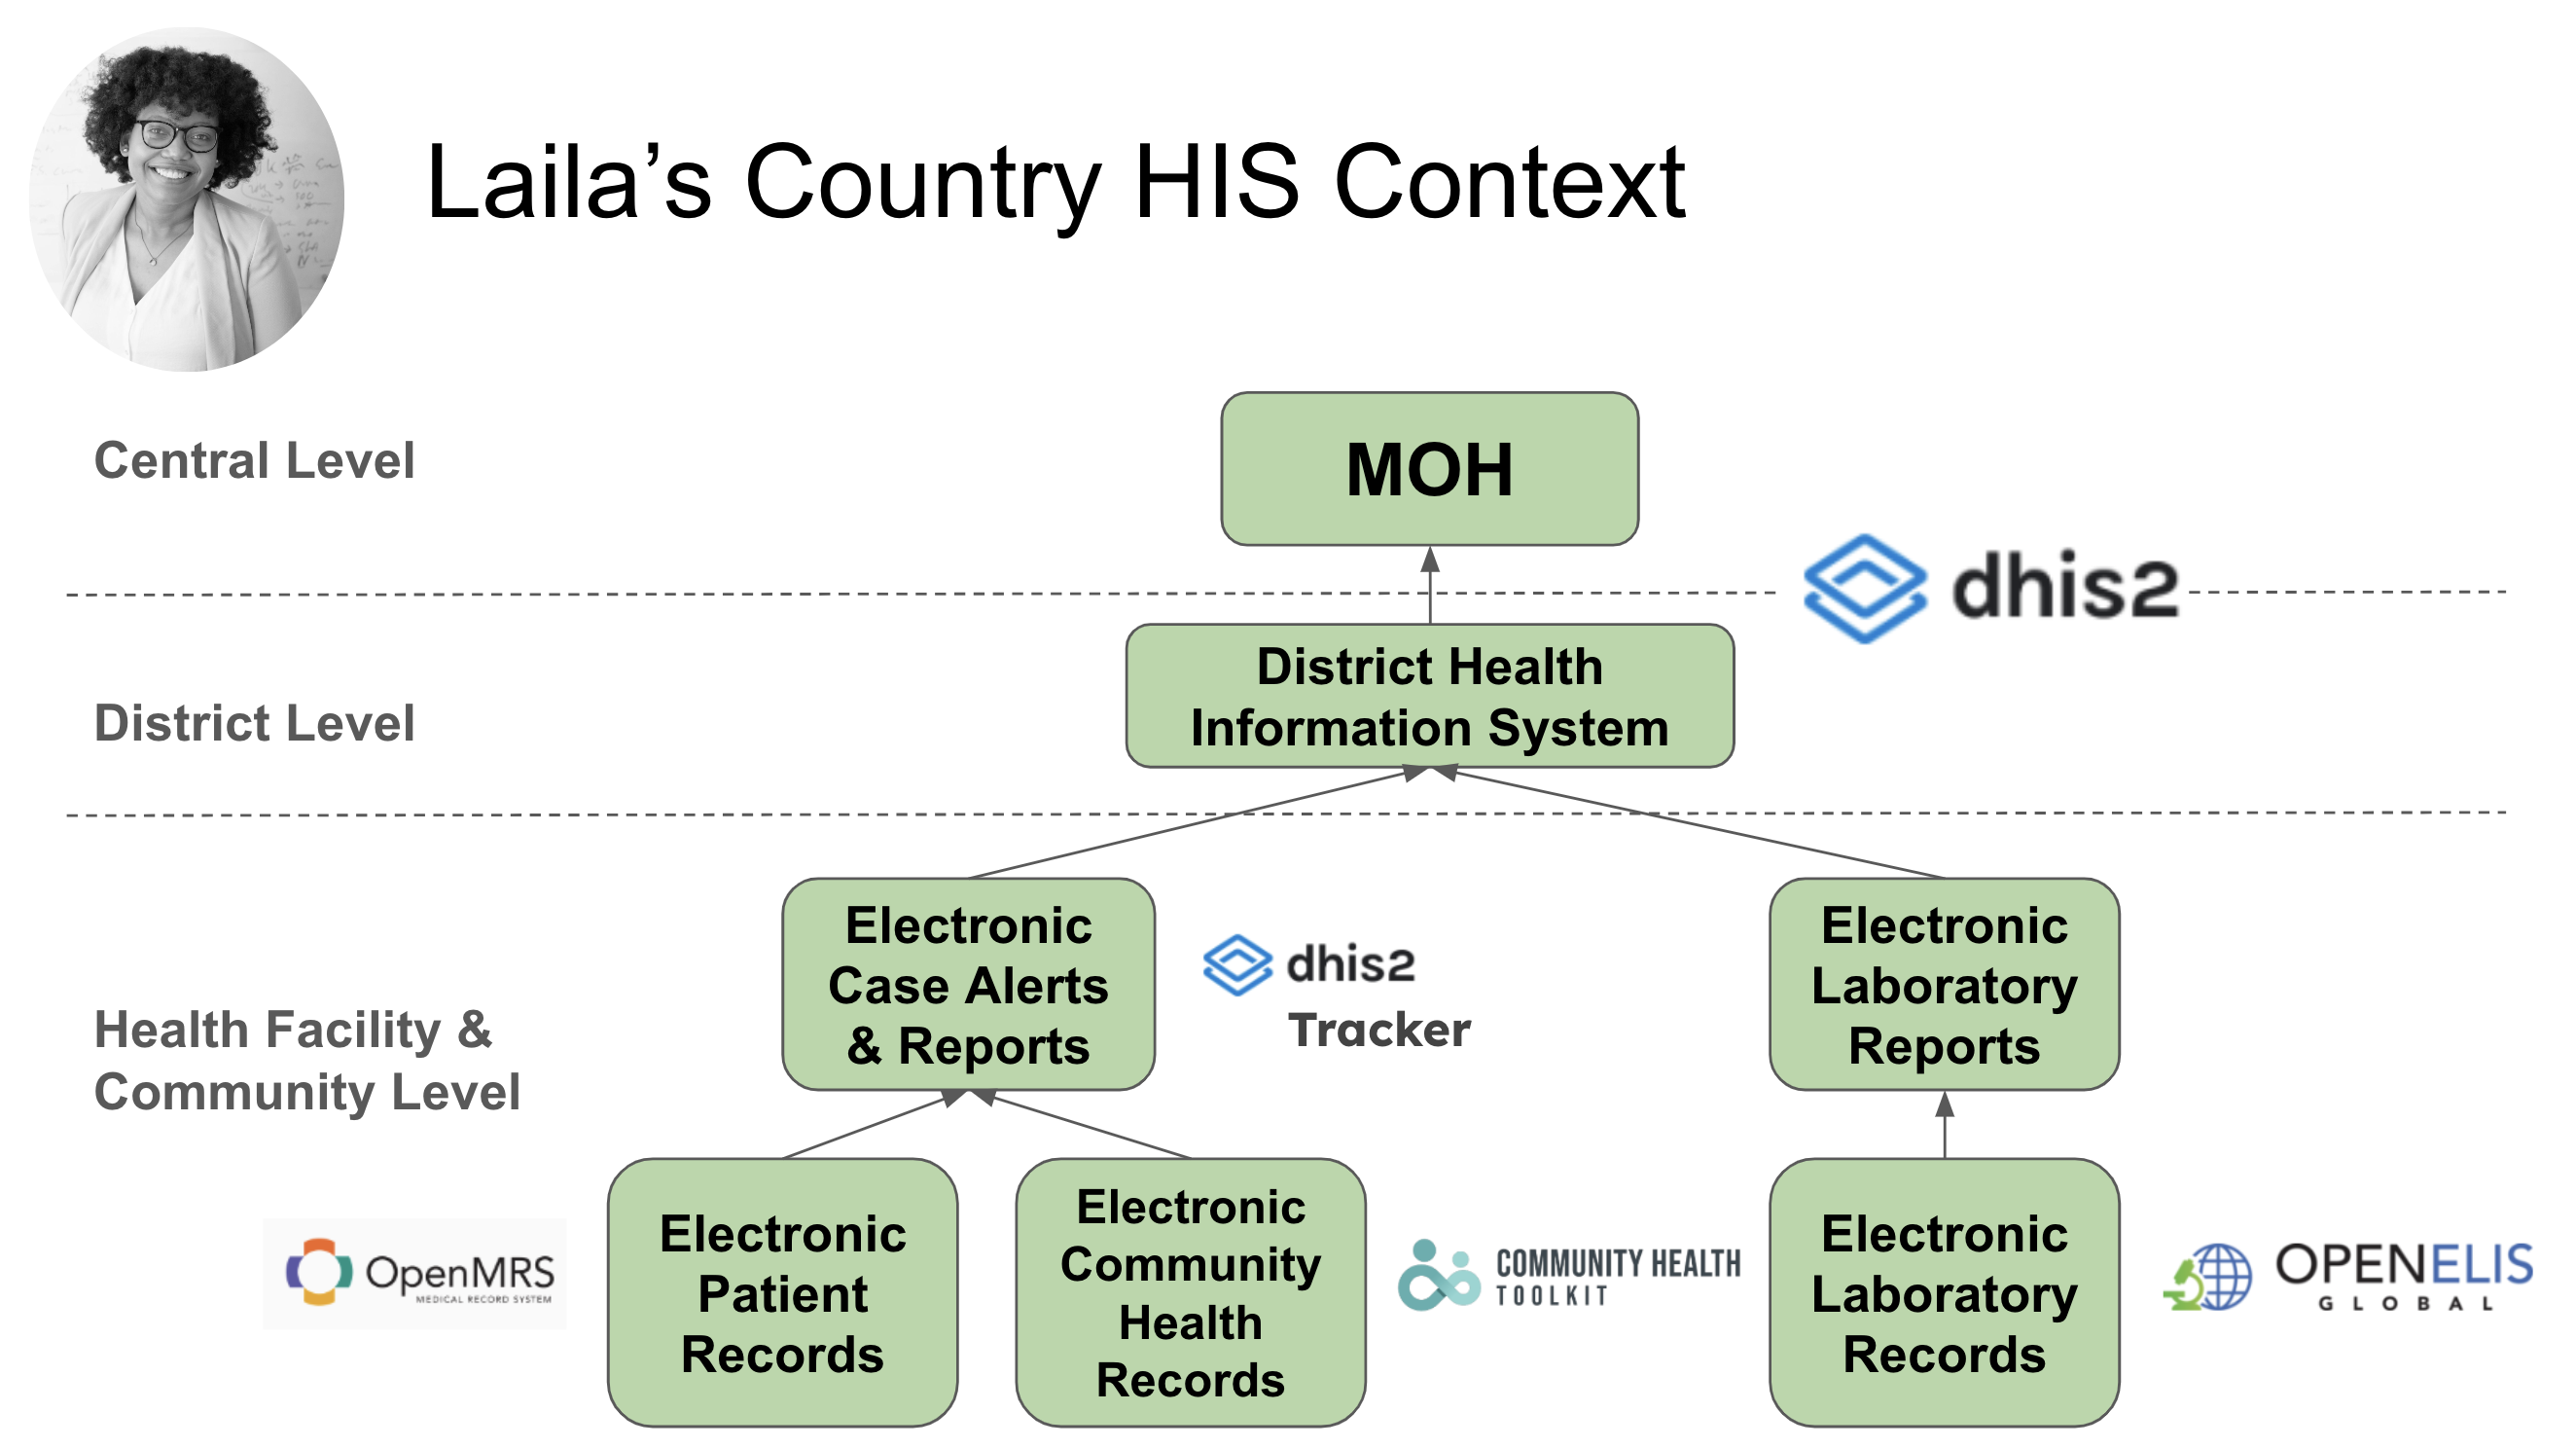

*Follow the case and laboratory reporting branches to the district health information system and Ministry of Health (MOH). Ask who can access each system.*

**Learning objective:** **Trace** a case-report path and a laboratory-report path from source records to MOH.

## Laila's case

Kukuna Health Center calls about reports of fever and rash. Laila's team must prepare a surveillance summary. She needs to know where the data originates, which paper and electronic systems hold it, and who can use each system.

In the diagram above, build two **electronic** paths. For each path, use **Move up** and **Move down** to put the four stages in the order information travels. Select a stage first, then move it. Both lists start out of order. Run **Check my map** after moving stages in both lists. You can correct a route and check again; the Learning panel records each attempt.

Trace the fever-and-rash reporting path shown in the diagram.


In [ ]:
# Run once to display the route controls. Re-running resets both routes.
try:
    import ipywidgets as widgets
except ImportError:
    import piplite
    await piplite.install("ipywidgets==8.1.7")
    import ipywidgets as widgets
from IPython.display import display

case_order = [
    "District health information system",
    "Electronic patient records",
    "Ministry of Health",
    "Electronic case alerts and reports",
]
lab_order = [
    "Electronic laboratory reports",
    "Ministry of Health",
    "Electronic laboratory records",
    "District health information system",
]
case_moves = 0
lab_moves = 0
case_list = widgets.Select(options=case_order, rows=4, description="Case path", layout=widgets.Layout(width="650px"))
lab_list = widgets.Select(options=lab_order, rows=4, description="Lab path", layout=widgets.Layout(width="650px"))

def move_stage(stage_list, direction, route_name):
    global case_moves, lab_moves
    items = list(stage_list.options)
    selected = stage_list.value
    if selected not in items:
        return
    old = items.index(selected)
    new = old + direction
    if not 0 <= new < len(items):
        return
    items[old], items[new] = items[new], items[old]
    stage_list.options = items
    stage_list.value = selected
    if route_name == "case":
        case_moves += 1
    else:
        lab_moves += 1

def route_controls(stage_list, route_name):
    up = widgets.Button(description="Move up", icon="arrow-up")
    down = widgets.Button(description="Move down", icon="arrow-down")
    up.on_click(lambda _: move_stage(stage_list, -1, route_name))
    down.on_click(lambda _: move_stage(stage_list, 1, route_name))
    return widgets.VBox([stage_list, widgets.HBox([up, down])])

def collect_system_map():
    return {
        "case": list(case_list.options),
        "lab": list(lab_list.options),
        "case_moves": case_moves,
        "lab_moves": lab_moves,
    }

display(widgets.VBox([
    widgets.HTML("<b>1. Health facility case-report path</b>"),
    route_controls(case_list, "case"),
    widgets.HTML("<b>2. Laboratory-report path</b>"),
    route_controls(lab_list, "lab"),
]))


In [ ]:
# Check my map: run this cell after moving stages in both paths.
system_map = collect_system_map()
print("Case path:", " → ".join(system_map["case"]))
print("Lab path: ", " → ".join(system_map["lab"]))


## Reflect on system use

Who needs each case or laboratory report? Name one access question you would verify with the district team. Your reflection is not automatically scored.

## Continue the case

Use the **Learning** panel for the next activity. If a route was incorrect,
follow each arrow in the diagram and try the same map again.


## References

- UCSF-IGHS, *FETP JupyterBook*, Unit 2 HIS case study and group work; adapted with a local system map.
- [Unit 2 course slides (local PDF)](../../readings/ucsf/assets/unit-2-version-2-slides.pdf).
